# Validasi Silang dengan Pipeline dan Tuning Hyperparameter

Course 2: Supervised Learning

Pada percobaan ini saya mempelajari cara merangkai beberapa langkah pemrosesan data dengan `Pipeline`, melakukan cross validation dengan `KFold`, `cross_val_predict`, dan `GridSearchCV`, lalu memakainya untuk mencari hyperparameter terbaik pada regresi Lasso dan Ridge.

## Dataset

Datanya `boston_housing_clean.pickle`, berisi dictionary dengan DataFrame harga rumah di Boston (`dataframe`) dan keterangan kolomnya (`description`). Targetnya `MEDV`, median harga rumah dalam ribuan dolar. Dibaca langsung dari link:

https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/boston_housing_clean.pickle

Catatan: dataset Boston asli sudah dihapus dari scikit-learn karena salah satu fiturnya bermasalah secara etika. Di sini dipakai hanya untuk latihan teknik cross validation dan regularisasi.

## 1. Import dan baca data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_predict, GridSearchCV
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [2]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/boston_housing_clean.pickle"
boston = pd.read_pickle(URL)
print(boston.keys())

df = boston["dataframe"]
X = df.drop(columns="MEDV")
y = df["MEDV"]
print(X.shape)
df.head()

dict_keys(['dataframe', 'description'])
(506, 13)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


## 2. Cross validation manual dengan KFold

Diskusi: kalau data dibagi 3 lipatan dan ingin memperkirakan seberapa baik regresi linear pada data baru, langkahnya:

1. Ambil lipatan 1 sebagai data uji, gabungkan lipatan 2 dan 3 sebagai data latih.
2. Latih model pada data latih, prediksi data uji, hitung skornya.
3. Ulangi untuk lipatan 2 dan lipatan 3 sebagai data uji.
4. Rata-ratakan tiga skor tersebut.

In [3]:
kf = KFold(n_splits=3, shuffle=True, random_state=72018)

for i, (idx_tr, idx_te) in enumerate(kf.split(X), start=1):
    print(f"lipatan {i}: train={len(idx_tr)}, test={len(idx_te)}, contoh index test={idx_te[:5]}")

lipatan 1: train=337, test=169, contoh index test=[ 0  2  6  9 15]
lipatan 2: train=337, test=169, contoh index test=[1 3 4 5 7]
lipatan 3: train=338, test=168, contoh index test=[10 11 12 13 18]


In [4]:
def r2_manual(pakai_scaler):
    skor = []
    for idx_tr, idx_te in kf.split(X):
        Xa, Xb = X.iloc[idx_tr], X.iloc[idx_te]
        ya, yb = y.iloc[idx_tr], y.iloc[idx_te]
        if pakai_scaler:
            sc = StandardScaler().fit(Xa)      # scaler hanya belajar dari data latih
            Xa, Xb = sc.transform(Xa), sc.transform(Xb)
        model = LinearRegression().fit(Xa, ya)
        skor.append(r2_score(yb, model.predict(Xb)))
    return np.array(skor)

print("tanpa scaling:", r2_manual(False).round(4))
print("dengan scaling:", r2_manual(True).round(4))

tanpa scaling: [0.6719 0.7485 0.6977]
dengan scaling: [0.6719 0.7485 0.6977]


Kedua hasil sama karena regresi linear tanpa regularisasi tidak terpengaruh skala fitur. Tapi menulis loop begini jadi merepotkan kalau langkahnya bertambah. Di sinilah `Pipeline` dan `cross_val_predict` membantu.

## 3. Pipeline dan cross_val_predict

`Pipeline` merangkai langkah-langkah yang dijalankan berurutan. Tiap langkah ditulis sebagai pasangan `(nama, objek)`. `cross_val_predict` lalu melakukan K-fold: pada tiap putaran seluruh pipeline di-fit pada data latih dan dipakai memprediksi data uji, jadi scaling otomatis hanya belajar dari data latih.

In [5]:
pipa = Pipeline([("scaler", StandardScaler()), ("regresi", LinearRegression())])
pred = cross_val_predict(pipa, X, y, cv=kf)

print("R2 (cross_val_predict):", round(r2_score(y, pred), 4))
print("rata-rata R2 manual    :", round(r2_manual(True).mean(), 4))

R2 (cross_val_predict): 0.7064
rata-rata R2 manual    : 0.706


Hasilnya hampir sama dengan versi manual (selisih kecil karena `r2_score` dihitung dari semua prediksi sekaligus, bukan dirata-ratakan per lipatan). Setiap baris diprediksi oleh model yang tidak melihat baris itu saat training. Setelah ini `pipa` masih belum terlatih, jadi untuk memprediksi data baru tetap perlu di-`fit` dulu.

## 4. Tuning hyperparameter

Tuning hyperparameter berarti memilih nilai pengaturan model (misalnya `alpha` pada Lasso) yang memberi performa terbaik pada data yang tidak dipakai untuk training, diukur lewat cross validation. Kandidat `alpha` dibuat dengan `np.geomspace` (jaraknya eksponensial).

In [6]:
def skor_alpha(kelas, alphas, derajat=1, **kw):
    hasil = []
    for a in alphas:
        pipa = Pipeline([
            ("scaler", StandardScaler()),
            ("poly", PolynomialFeatures(degree=derajat, include_bias=False)),
            ("reg", kelas(alpha=a, **kw)),
        ])
        pred = cross_val_predict(pipa, X, y, cv=kf)
        hasil.append(r2_score(y, pred))
    return np.array(hasil)

alphas_lasso = np.geomspace(1e-9, 1, 10)
skor_lasso_1 = skor_alpha(Lasso, alphas_lasso, derajat=1, max_iter=100000)
pd.DataFrame({"alpha": alphas_lasso, "R2 cv": skor_lasso_1})

,alpha,R2 cv
0,1.000000e-09,0.706353
1,1.000000e-08,0.706353
2,1.000000e-07,0.706353
3,1.000000e-06,0.706353
4,1.000000e-05,0.706354
5,1.000000e-04,0.706361
6,1.000000e-03,0.706433
7,1.000000e-02,0.707087
8,1.000000e-01,0.705838
9,1.000000e+00,0.651272


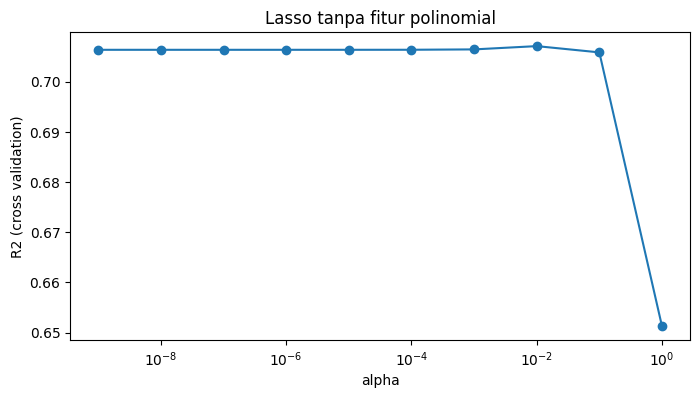

In [7]:
plt.figure(figsize=(8, 4))
plt.semilogx(alphas_lasso, skor_lasso_1, "-o")
plt.xlabel("alpha")
plt.ylabel("R2 (cross validation)")
plt.title("Lasso tanpa fitur polinomial")
plt.show()

Alpha yang kecil mendekati regresi linear biasa. Alpha yang terlalu besar membuat hampir semua koefisien menjadi nol sehingga skornya turun.

### Latihan: tambahkan `PolynomialFeatures` ke pipeline

Urutannya penting: data di-scale dulu, baru dibuat fitur polinomial, lalu masuk ke Lasso. Dengan fitur polinomial derajat 2, model punya lebih banyak fitur, dan Lasso bertugas menyaring yang tidak berguna.

alpha terbaik: 0.0156 | R2 cv: 0.8505


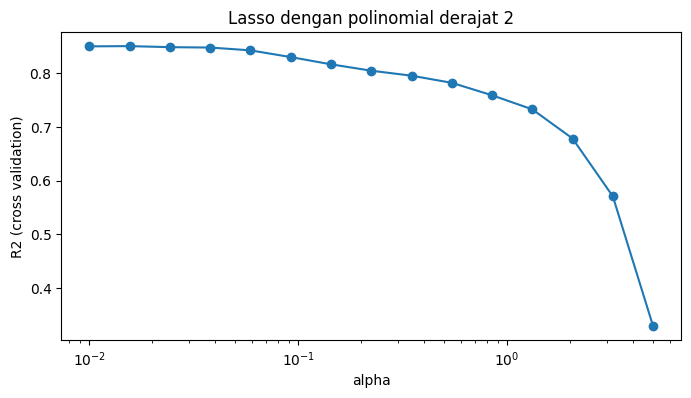

In [8]:
alphas_lasso2 = np.geomspace(0.01, 5, 15)
skor_lasso_2 = skor_alpha(Lasso, alphas_lasso2, derajat=2, max_iter=100000)

terbaik_lasso = alphas_lasso2[skor_lasso_2.argmax()]
print("alpha terbaik:", round(terbaik_lasso, 4), "| R2 cv:", round(skor_lasso_2.max(), 4))

plt.figure(figsize=(8, 4))
plt.semilogx(alphas_lasso2, skor_lasso_2, "-o")
plt.xlabel("alpha")
plt.ylabel("R2 (cross validation)")
plt.title("Lasso dengan polinomial derajat 2")
plt.show()

### Latihan: lakukan hal yang sama dengan Ridge

alpha terbaik: 17.1906 | R2 cv: 0.8502


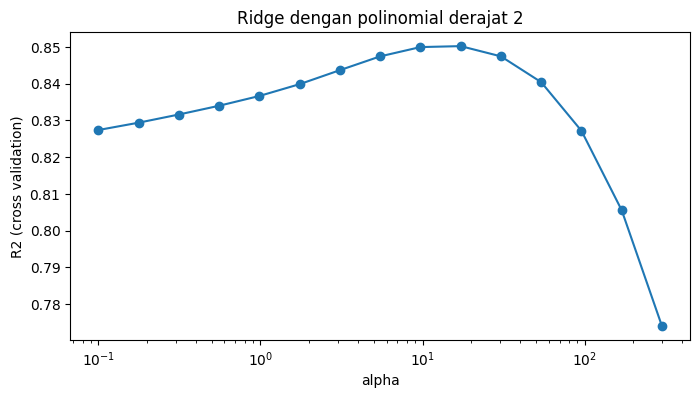

In [9]:
alphas_ridge = np.geomspace(0.1, 300, 15)
skor_ridge = skor_alpha(Ridge, alphas_ridge, derajat=2)

terbaik_ridge = alphas_ridge[skor_ridge.argmax()]
print("alpha terbaik:", round(terbaik_ridge, 4), "| R2 cv:", round(skor_ridge.max(), 4))

plt.figure(figsize=(8, 4))
plt.semilogx(alphas_ridge, skor_ridge, "-o")
plt.xlabel("alpha")
plt.ylabel("R2 (cross validation)")
plt.title("Ridge dengan polinomial derajat 2")
plt.show()

In [10]:
pd.Series({
    "Regresi linear": r2_manual(True).mean(),
    "Lasso (poly 2)": skor_lasso_2.max(),
    "Ridge (poly 2)": skor_ridge.max(),
}).round(4)

,0
Regresi linear,0.7060
Lasso (poly 2),0.8505
Ridge (poly 2),0.8502


Dari tabel di atas bisa dilihat model mana yang terbaik. Lasso dan Ridge dengan alpha yang dituning biasanya mengungguli regresi linear biasa pada fitur polinomial, karena regularisasi mengendalikan overfitting.

### Latihan: koefisien terbesar pada model terbaik

Aku latih model Lasso terbaik pada seluruh data, lalu lihat fitur polinomial mana yang koefisiennya terbesar. Nama fiturnya diambil dari `get_feature_names_out` supaya mudah dibaca.

In [11]:
model_akhir = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("reg", Lasso(alpha=terbaik_lasso, max_iter=100000)),
]).fit(X, y)

nama_fitur = model_akhir["poly"].get_feature_names_out(X.columns)
koef = pd.Series(model_akhir["reg"].coef_, index=nama_fitur)

print("koefisien tidak nol:", int((koef != 0).sum()), "dari", len(koef))
koef.reindex(koef.abs().sort_values(ascending=False).index).head(10).round(3)

koefisien tidak nol: 75 dari 104


,0
CRIM CHAS,4.156
RM,3.399
RAD^2,-3.323
LSTAT,-3.301
RAD TAX,3.012
DIS,-2.874
TAX PTRATIO,1.980
INDUS NOX,1.450
AGE RAD,1.433
AGE,-1.259


## 5. GridSearchCV

Pola yang kita pakai di atas (loop hyperparameter lalu hitung skor cross validation) sudah disediakan oleh `GridSearchCV`. Ia menerima pipeline dan kamus parameter yang mau dicari, mencoba semua kombinasinya dengan cross validation, lalu melatih ulang model terbaik pada seluruh data.

In [12]:
pipa_grid = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("ridge", Ridge()),
])

parameter = {
    "poly__degree": [1, 2, 3],
    "ridge__alpha": np.geomspace(1, 100, 10),
}

grid = GridSearchCV(pipa_grid, parameter, cv=kf)
grid.fit(X, y)

print("skor terbaik   :", round(grid.best_score_, 4))
print("parameter terbaik:", grid.best_params_)

skor terbaik   : 0.8504
parameter terbaik: {'poly__degree': 2, 'ridge__alpha': np.float64(12.91549665014884)}


In [13]:
hasil_grid = pd.DataFrame(grid.cv_results_)
hasil_grid[["param_poly__degree", "param_ridge__alpha", "mean_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(5)

,param_poly__degree,param_ridge__alpha,mean_test_score
15,2,12.915497,0.850364
16,2,21.544347,0.849969
14,2,7.742637,0.848590
17,2,35.938137,0.846789
13,2,4.641589,0.845293


`grid` sudah berupa model yang terlatih, jadi bisa langsung dipakai `grid.predict(...)` untuk data baru. Skor R2 yang dihitung dari seluruh data akan terlalu optimis karena modelnya sudah melihat semua data tersebut.